# Experiment 5: Implementing Feature Selection Techniques on Autonomous-System Data

**Dataset:** Indian subdivision-wise rainfall dataset (`Sub_Division_IMD_2017(2).csv`).

## Aim
Identify and select relevant features using statistical and machine-learning-based feature selection techniques.

## Dataset and modelling choice
The CSV is environmental rainfall data, not a direct autonomous-vehicle/robot sensor dataset. For a reproducible feature-selection exercise, the target is **ANNUAL rainfall**, predicted from the 12 monthly rainfall attributes. Seasonal aggregate columns are excluded because they overlap mathematically with the target and could cause target leakage. `SUBDIVISION` and `YEAR` are retained as identifiers/context, not numeric predictors.

## Methods
- Filter: Pearson correlation and mutual information
- Wrapper: Recursive Feature Elimination (RFE)
- Embedded: Random Forest feature importance
- Model comparison: Random Forest regression with all 12 predictors versus the top 6 tree-ranked predictors

The notebook follows the activities in the supplied Experiment 5 sheet (pages 2–3).

In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Note: you may need to restart the kernel to use updated packages.


Dataset shape: (4188, 19)


,SUBDIVISION,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,ANNUAL,JF,MAM,JJAS,OND
0,Andaman & Nicobar Islands,1901,49.2,87.1,29.2,2.3,528.8,517.5,365.1,481.1,332.6,388.5,558.2,33.6,3373.2,136.3,560.3,1696.3,980.3
1,Andaman & Nicobar Islands,1902,0.0,159.8,12.2,0.0,446.1,537.1,228.9,753.7,666.2,197.2,359.0,160.5,3520.7,159.8,458.3,2185.9,716.7
2,Andaman & Nicobar Islands,1903,12.7,144.0,0.0,1.0,235.1,479.9,728.4,326.7,339.0,181.2,284.4,225.0,2957.4,156.7,236.1,1874.0,690.6
3,Andaman & Nicobar Islands,1904,9.4,14.7,0.0,202.4,304.5,495.1,502.0,160.1,820.4,222.2,308.7,40.1,3079.6,24.1,506.9,1977.6,571.0
4,Andaman & Nicobar Islands,1905,1.3,0.0,3.3,26.9,279.5,628.7,368.7,330.5,297.0,260.7,25.4,344.7,2566.7,1.3,309.7,1624.9,630.8


\nMissing values:


,Missing values
SUBDIVISION,0
YEAR,0
JAN,4
FEB,3
MAR,6
APR,4
MAY,3
JUN,5
JUL,7
AUG,4


Independent variables: ['JAN', 'FEB', 'MAR', 'APR', 'MAY', 'JUN', 'JUL', 'AUG', 'SEP', 'OCT', 'NOV', 'DEC']
Dependent variable: ANNUAL
Rows available for modelling: 4162
Missing values in predictors after imputation: 0
\nCorrelation with annual rainfall:


,Correlation with ANNUAL
JUN,0.890985
JUL,0.811441
AUG,0.759260
SEP,0.717022
MAY,0.697518
OCT,0.588482
APR,0.576167
MAR,0.323516
NOV,0.309427
DEC,0.208668


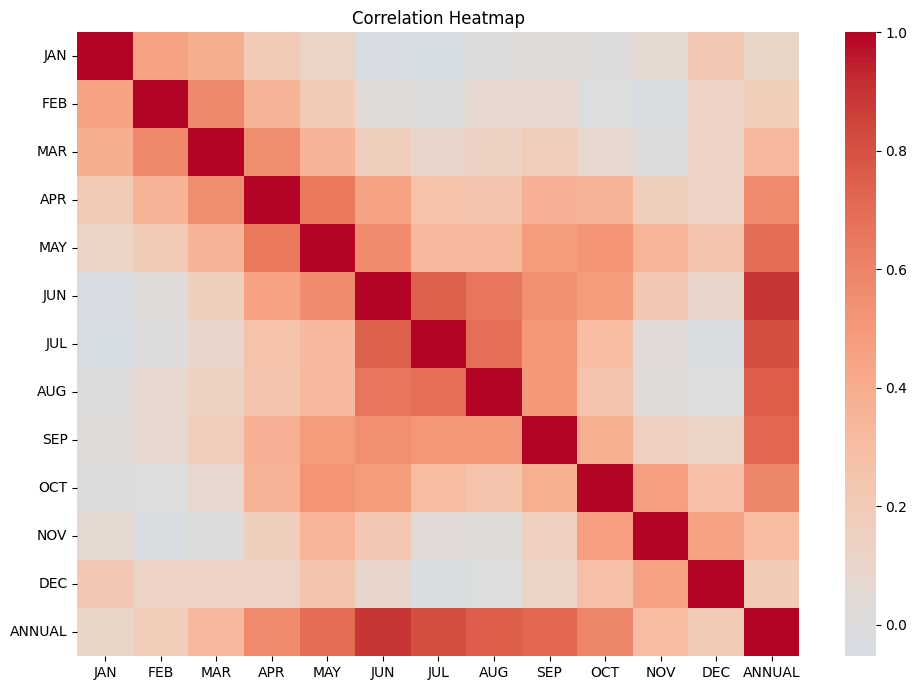

Top 6 correlation-selected features: ['JUN', 'JUL', 'AUG', 'SEP', 'MAY', 'OCT']


\nMutual information scores:


,Mutual information
JUN,0.677778
JUL,0.535748
AUG,0.473491
SEP,0.390207
MAY,0.357731
APR,0.276315
OCT,0.245917
NOV,0.128699
MAR,0.098272
FEB,0.067453


Top 6 mutual-information features: ['JUN', 'JUL', 'AUG', 'SEP', 'MAY', 'APR']


\nRFE selected features: ['APR', 'MAY', 'JUN', 'JUL', 'AUG', 'SEP']


\nRandom Forest feature importance:


,Importance
JUN,0.718369
JUL,0.081378
AUG,0.066397
MAY,0.056013
SEP,0.026528
OCT,0.016049
APR,0.011724
FEB,0.006752
NOV,0.004880
MAR,0.004704


Top 6 tree-importance features: ['JUN', 'JUL', 'AUG', 'MAY', 'SEP', 'OCT']


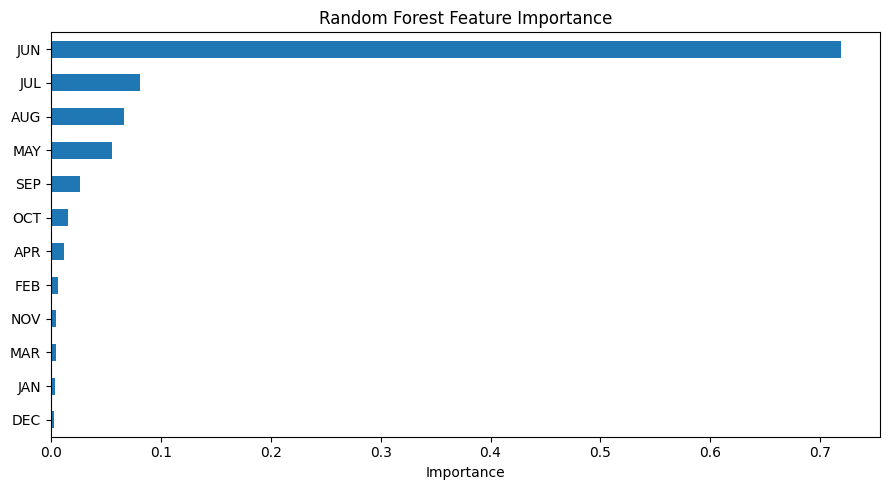

\nFeature selection comparison:


,Correlation,Mutual Information,RFE,Tree Importance
0,JUN,JUN,APR,JUN
1,JUL,JUL,MAY,JUL
2,AUG,AUG,JUN,AUG
3,SEP,SEP,JUL,MAY
4,MAY,MAY,AUG,SEP
5,OCT,APR,SEP,OCT


\nModel performance comparison:


,MAE,RMSE,R2,Fit time (seconds)
All 12 monthly features,89.4034,150.4114,0.9737,1.7723
Selected 6 features,109.6383,173.8347,0.9648,0.8933


\nConclusion:
Feature selection was performed using correlation, mutual information, RFE and Random Forest importance.
The same Random Forest regression model was evaluated with all monthly predictors and the top six tree-ranked predictors.
Compare R2, MAE, RMSE and fit time above to judge the trade-off between predictive performance and complexity.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import mutual_info_regression, RFE
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Load dataset
df = pd.read_csv("Sub_Division_IMD_2017(2).csv")
print("Dataset shape:", df.shape)
display(df.head())
print("\\nMissing values:")
display(df.isnull().sum().to_frame("Missing values"))

# 2. Define independent and dependent variables.
# Predict ANNUAL rainfall using monthly rainfall columns only.
# Seasonal aggregates are excluded to avoid target leakage/redundant sums.
feature_cols = ["JAN", "FEB", "MAR", "APR", "MAY", "JUN",
                "JUL", "AUG", "SEP", "OCT", "NOV", "DEC"]
target_col = "ANNUAL"

data = df[feature_cols + [target_col]].copy()
data = data.dropna(subset=[target_col])
X = data[feature_cols]
y = data[target_col]

print("Independent variables:", feature_cols)
print("Dependent variable:", target_col)
print("Rows available for modelling:", len(data))

# 3. Basic cleaning: median imputation for missing monthly values
imputer = SimpleImputer(strategy="median")
X_clean = pd.DataFrame(imputer.fit_transform(X), columns=feature_cols, index=X.index)
print("Missing values in predictors after imputation:", int(X_clean.isna().sum().sum()))

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X_clean, y, test_size=0.2, random_state=42
)

# 4. Correlation analysis (filter method)
corr = pd.concat([X_clean, y.rename(target_col)], axis=1).corr()
target_corr = corr[target_col].drop(target_col).sort_values(key=np.abs, ascending=False)
print("\\nCorrelation with annual rainfall:")
display(target_corr.to_frame("Correlation with ANNUAL"))
plt.figure(figsize=(10, 7))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

# Select top 6 features by absolute Pearson correlation (filter selection)
correlation_selected = target_corr.abs().head(6).index.tolist()
print("Top 6 correlation-selected features:", correlation_selected)

# Mutual information filter method, fitted on training data only
mi_scores = mutual_info_regression(X_train, y_train, random_state=42)
mi_series = pd.Series(mi_scores, index=feature_cols).sort_values(ascending=False)
print("\\nMutual information scores:")
display(mi_series.to_frame("Mutual information"))
mi_selected = mi_series.head(6).index.tolist()
print("Top 6 mutual-information features:", mi_selected)

# 5. Wrapper method: Recursive Feature Elimination (RFE)
rfe_estimator = RandomForestRegressor(n_estimators=150, random_state=42, n_jobs=-1)
rfe = RFE(estimator=rfe_estimator, n_features_to_select=6, step=1)
rfe.fit(X_train, y_train)
rfe_selected = X_train.columns[rfe.support_].tolist()
print("\\nRFE selected features:", rfe_selected)

# 6. Embedded method: tree-based feature importance
tree_model = RandomForestRegressor(n_estimators=250, random_state=42, n_jobs=-1)
tree_model.fit(X_train, y_train)
importance = pd.Series(tree_model.feature_importances_, index=feature_cols).sort_values(ascending=False)
print("\\nRandom Forest feature importance:")
display(importance.to_frame("Importance"))
tree_selected = importance.head(6).index.tolist()
print("Top 6 tree-importance features:", tree_selected)

plt.figure(figsize=(9, 5))
importance.sort_values().plot(kind="barh")
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

# 7. Compare selected features across methods
selection_comparison = pd.DataFrame({
    "Correlation": pd.Series(correlation_selected),
    "Mutual Information": pd.Series(mi_selected),
    "RFE": pd.Series(rfe_selected),
    "Tree Importance": pd.Series(tree_selected)
})
print("\\nFeature selection comparison:")
display(selection_comparison)

# 8. Train same model with all features and selected features.
# Use the top 6 tree-importance features for the selected-feature model.
def evaluate_model(model, Xtr, Xte, ytr, yte):
    start = time.perf_counter()
    model.fit(Xtr, ytr)
    fit_time = time.perf_counter() - start
    pred = model.predict(Xte)
    return {
        "MAE": mean_absolute_error(yte, pred),
        "RMSE": np.sqrt(mean_squared_error(yte, pred)),
        "R2": r2_score(yte, pred),
        "Fit time (seconds)": fit_time
    }

all_model = RandomForestRegressor(n_estimators=250, random_state=42, n_jobs=-1)
selected_model = RandomForestRegressor(n_estimators=250, random_state=42, n_jobs=-1)

all_results = evaluate_model(all_model, X_train, X_test, y_train, y_test)
selected_results = evaluate_model(
    selected_model, X_train[tree_selected], X_test[tree_selected], y_train, y_test
)

performance = pd.DataFrame(
    [all_results, selected_results],
    index=["All 12 monthly features", "Selected 6 features"]
)
print("\\nModel performance comparison:")
display(performance.round(4))

print("\\nConclusion:")
print("Feature selection was performed using correlation, mutual information, RFE and Random Forest importance.")
print("The same Random Forest regression model was evaluated with all monthly predictors and the top six tree-ranked predictors.")
print("Compare R2, MAE, RMSE and fit time above to judge the trade-off between predictive performance and complexity.")
